# Material characterization of printed PA6 and PA6-CF

Reduction of the coupon tests of **Section 4.3** of the thesis ([`docs/TO_Final_Inform_FLP.pdf`](../docs/TO_Final_Inform_FLP.pdf)) and derivation of the material constants of **Section 4.4**, which feed Block 1 of `Final.ipynb`.

Each material is characterized with two standard tests and five specimens per test, 20 curves in total:

| Test | Standard | Load direction | Specimen | Gives |
|---|---|---|---|---|
| Uniaxial tension | ASTM D638 | Parallel to the layers | Dog-bone, gauge section 13.0 x 3.20 mm, gauge length 50.0 mm | $E_r$, $S_{y,T}$, $S_{u,T}$ |
| Uniaxial compression | ASTM D695 | Along the build direction $z$ | Prism, 12.7 x 12.7 x 50.8 mm | $E_z$, $S_y$ |

All the specimens share the printing parameters of Table 4.2.2, including the 35 % gyroid infill, so the results are homogenized properties of the printed material.

**Inputs:** `data/characterization/{PA6,PA6CF}_{1..5}_{T,C}.txt`. **Outputs:** `results/characterization/`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import linregress

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "characterization"
OUT = ROOT / "results" / "characterization"
OUT.mkdir(parents=True, exist_ok=True)

# Nominal specimen geometry (Sec. 4.3.1)
AREA_T, L0_T = 13.0 * 3.20, 50.0       # Tension: gauge section [mm2] and gauge length [mm]
AREA_C, L0_C = 12.7 * 12.7, 50.8       # Compression: section [mm2] and height [mm]

# Data reduction settings (Sec. 4.3.2)
ELASTIC_WINDOW = (0.001, 0.005)        # Strain range of the least-squares fit for the modulus
OFFSET = 0.002                         # 0.2 % offset for the yield strength
PREMATURE_RATIO = 0.80                 # Tension: failure below 80 % of the batch's highest strength is premature

BATCHES = [("PA6", "T"), ("PA6CF", "T"), ("PA6", "C"), ("PA6CF", "C")]
LABEL = {"PA6": "PA6", "PA6CF": "PA6-CF"}

## 1. Reading the machine records

The records have a summary section followed by the raw data, and they are not uniform: the column order and the force unit (N or kN) change between tests. The loader reads both from the header, converts to kN and mm, and tares the initial offsets.

In [2]:
def load_record(path):
    # Returns displacement [mm] and force [kN], tared and positive, from a machine record.
    lines = open(path, "r", encoding="latin1", errors="ignore").readlines()
    start, force_first, newtons = 3, False, False
    for i, line in enumerate(lines):
        if "Datos sin procesar" in line:       # Header written by the machine software ("raw data")
            start = i + 3
            header = lines[i + 1].split(";")[0].lower()
            force_first = ("force" in header) or ("fuerza" in header)
            units = lines[i + 2].replace('"', "").replace(" ", "")
            newtons = ("(N)" in units) and ("(kN)" not in units)
            break
    df = pd.read_csv(path, sep=";", skiprows=start, names=["a", "b"], encoding="latin1")
    to_float = lambda col: df[col].astype(str).str.replace('"', "").str.replace(",", ".").astype(float).to_numpy()
    disp, force = (to_float("b"), to_float("a")) if force_first else (to_float("a"), to_float("b"))
    force = force / 1000.0 if newtons else force
    return np.abs(disp - disp[0]), np.abs(force - force[0])

## 2. Reduction of one specimen (Sec. 4.3.2)

The engineering stress and strain use the nominal section and gauge length of each specimen.

- **Modulus:** slope of a least-squares fit in the strain window of 0.1 % to 0.5 %.
- **Yield strength:** last crossing between the curve and the line of slope $E$ shifted by the 0.2 % offset.
- **Ultimate strength:** largest stress of the curve.

Three PA6 compression prisms have no crossing, because their modulus in the fit window is lowered by the initial seating of the curve and the offset line stays below the curve. For these prisms the original analysis uses the 80th percentile of the stress record, and the table below identifies them in the column `Sy_method`.

In [3]:
def reduce_specimen(disp, force, area, length):
    # Engineering curve and properties of one specimen.
    stress = force * 1000.0 / area
    strain = disp / length
    in_window = (strain >= ELASTIC_WINDOW[0]) & (strain <= ELASTIC_WINDOW[1])
    fit = linregress(strain[in_window], stress[in_window])
    E = fit.slope
    crossings = np.where(np.diff(np.sign(stress - E * (strain - OFFSET))))[0]
    if len(crossings) > 0:
        i_y = crossings[-1]
        Sy, method = stress[i_y], "0.2 % offset"
    else:
        Sy = np.quantile(stress, 0.8)
        i_y = int(np.argmin(np.abs(stress - Sy)))
        method = "no crossing: 80th percentile"
    return dict(E=E, intercept=fit.intercept, Sy=Sy, Su=stress.max(), strain_y=strain[i_y], i_y=i_y, Sy_method=method, stress=stress, strain=strain)


specimens = []
for mat, test in BATCHES:
    area, length = (AREA_T, L0_T) if test == "T" else (AREA_C, L0_C)
    for n in range(1, 6):
        disp, force = load_record(DATA / f"{mat}_{n}_{test}.txt")
        specimens.append(dict(material=mat, test=test, specimen=n, **reduce_specimen(disp, force, area, length)))
specimens = pd.DataFrame(specimens)

# Premature failures, tension only: they started at the fillet, not in the gauge length (Sec. 4.3.2)
specimens["valid"] = True
for (mat, test), group in specimens.groupby(["material", "test"]):
    if test == "T":
        specimens.loc[group.index, "valid"] = group["Su"] >= PREMATURE_RATIO * group["Su"].max()

columns = ["material", "test", "specimen", "E", "Sy", "Su", "strain_y", "Sy_method", "valid"]
specimens[columns].to_csv(OUT / "specimen_results.csv", index=False)
specimens[columns].round(3)

,material,test,specimen,E,Sy,Su,strain_y,Sy_method,valid
0,PA6,T,1,856.574,14.663,50.721,0.019,0.2 % offset,True
1,PA6,T,2,856.574,29.808,35.096,0.037,0.2 % offset,False
2,PA6,T,3,856.574,25.481,35.577,0.032,0.2 % offset,False
3,PA6,T,4,856.574,25.481,50.962,0.032,0.2 % offset,True
4,PA6,T,5,770.917,37.019,37.019,0.049,0.2 % offset,False
5,PA6CF,T,1,2114.243,41.587,75.481,0.022,0.2 % offset,True
6,PA6CF,T,2,2082.971,43.269,76.202,0.023,0.2 % offset,True
7,PA6CF,T,3,2144.155,42.308,75.962,0.022,0.2 % offset,True
8,PA6CF,T,4,2084.330,41.587,75.962,0.022,0.2 % offset,True
9,PA6CF,T,5,1857.270,31.971,59.135,0.019,0.2 % offset,False


## 3. Batch results

Every specimen counts for the modulus, even one with a premature failure, because its elastic slope is still valid. The strengths average only the valid specimens. Specimens 2, 3 and 5 of PA6 failed prematurely in tension, so the PA6 tensile strengths are averages of two specimens.

In [4]:
rows = []
for mat, test in BATCHES:
    g = specimens[(specimens.material == mat) & (specimens.test == test)]
    v = g[g.valid]
    rows.append(dict(material=LABEL[mat], test={"T": "Tension", "C": "Compression"}[test], E_MPa=g.E.mean(), Sy_MPa=v.Sy.mean(), Su_MPa=v.Su.mean(),
                     strain_y_pct=100 * v.strain_y.mean(), n_E=len(g), n_strength=len(v)))
batches = pd.DataFrame(rows)
batches.to_csv(OUT / "batch_results.csv", index=False)
batches.round(2)

,material,test,E_MPa,Sy_MPa,Su_MPa,strain_y_pct,n_E,n_strength
0,PA6,Tension,839.44,20.07,50.84,2.53,5,2
1,PA6-CF,Tension,2056.59,42.19,75.90,2.18,5,4
2,PA6,Compression,294.32,53.30,54.49,9.87,5,5
3,PA6-CF,Compression,684.46,25.80,42.64,4.13,5,5


## 4. Figures

The first figure is **Figure 4.3.2** of the thesis. Dashed curves are premature failures. The other two show the elastic fits and the elastic regime up to the yield point of each specimen.

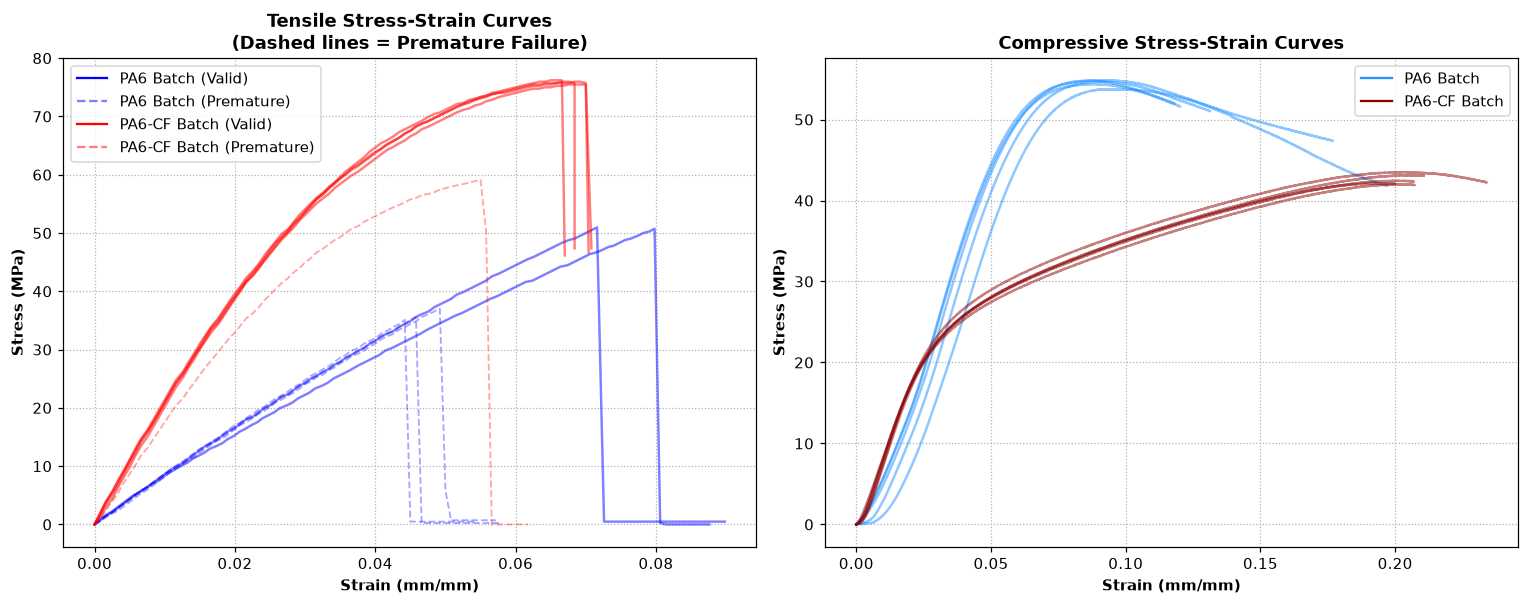

In [5]:
COLOR = {("PA6", "T"): "blue", ("PA6CF", "T"): "red", ("PA6", "C"): "dodgerblue", ("PA6CF", "C"): "darkred"}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.6), dpi=110)
for _, s in specimens.iterrows():
    ax = ax1 if s.test == "T" else ax2
    ax.plot(s.strain, s.stress, color=COLOR[(s.material, s.test)], alpha=0.5 if s.valid else 0.35, ls="-" if s.valid else "--", lw=1.6 if s.valid else 1.2)
for mat in ["PA6", "PA6CF"]:
    ax1.plot([], [], color=COLOR[(mat, "T")], label=f"{LABEL[mat]} Batch (Valid)")
    ax1.plot([], [], color=COLOR[(mat, "T")], ls="--", alpha=0.5, label=f"{LABEL[mat]} Batch (Premature)")
    ax2.plot([], [], color=COLOR[(mat, "C")], label=f"{LABEL[mat]} Batch")
ax1.set_title("Tensile Stress-Strain Curves\n(Dashed lines = Premature Failure)", fontweight="bold")
ax2.set_title("Compressive Stress-Strain Curves", fontweight="bold")
for ax in (ax1, ax2):
    ax.set_xlabel("Strain (mm/mm)", fontweight="bold"); ax.set_ylabel("Stress (MPa)", fontweight="bold"); ax.grid(True, ls=":"); ax.legend()
plt.tight_layout()
fig.savefig(OUT / "stress_strain_curves.png", dpi=300, bbox_inches="tight")
plt.show()

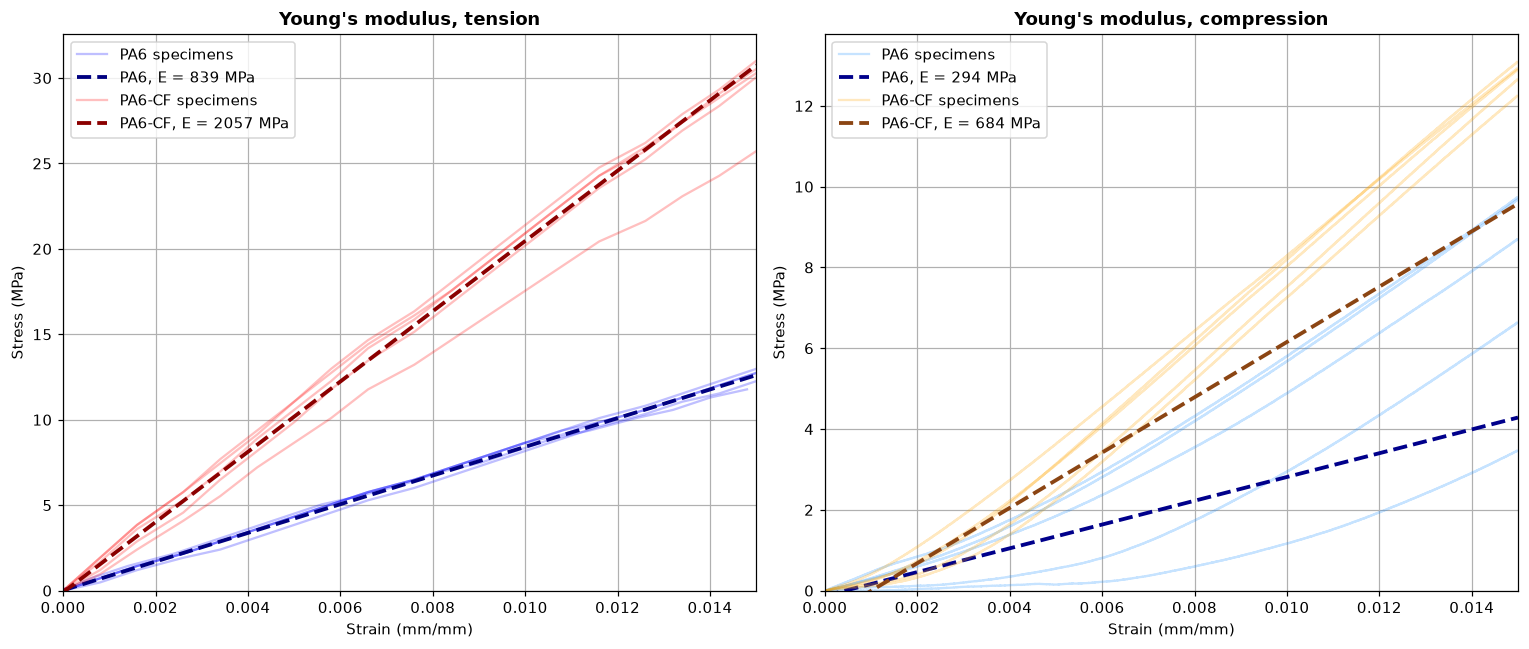

In [6]:
# Elastic range and mean tangent of each batch
fig, axes = plt.subplots(1, 2, figsize=(14, 6), dpi=110)
TANGENT = {("PA6", "T"): "navy", ("PA6CF", "T"): "darkred", ("PA6", "C"): "darkblue", ("PA6CF", "C"): "saddlebrown"}
CURVE = {("PA6", "T"): "blue", ("PA6CF", "T"): "red", ("PA6", "C"): "dodgerblue", ("PA6CF", "C"): "orange"}
for ax, test, title in [(axes[0], "T", "Young's modulus, tension"), (axes[1], "C", "Young's modulus, compression")]:
    for mat in ["PA6", "PA6CF"]:
        g = specimens[(specimens.material == mat) & (specimens.test == test)]
        for i, (_, s) in enumerate(g.iterrows()):
            z = s.strain <= 0.015
            ax.plot(s.strain[z], s.stress[z], color=CURVE[(mat, test)], alpha=0.25, label=f"{LABEL[mat]} specimens" if i == 0 else None)
        x_line = np.array([0, 0.015])
        ax.plot(x_line, g.E.mean() * x_line + g.intercept.mean(), "--", lw=2.5, color=TANGENT[(mat, test)], label=f"{LABEL[mat]}, E = {g.E.mean():.0f} MPa")
    ax.set_xlim(0, 0.015); ax.set_ylim(bottom=0); ax.set_title(title, fontweight="bold")
    ax.set_xlabel("Strain (mm/mm)"); ax.set_ylabel("Stress (MPa)"); ax.grid(True); ax.legend(loc="upper left")
plt.tight_layout()
fig.savefig(OUT / "young_modulus_fits.png", dpi=300, bbox_inches="tight")
plt.show()

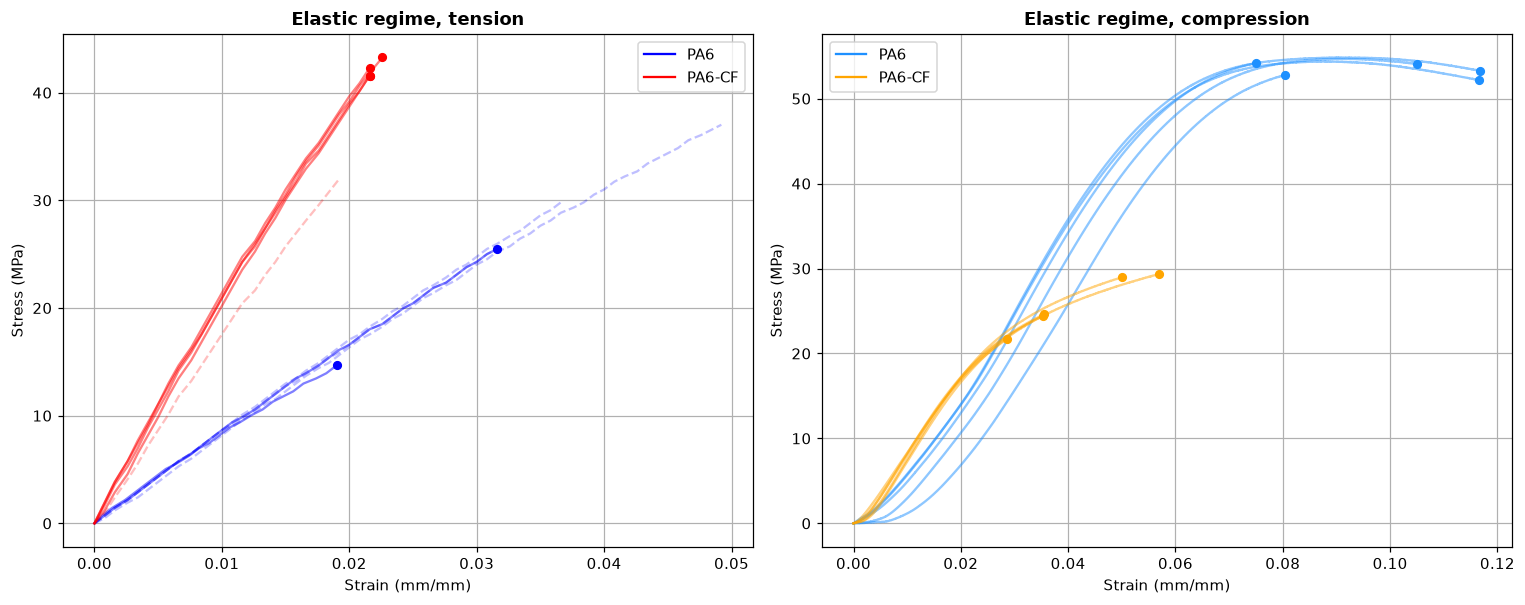

In [7]:
# Elastic regime: each curve up to its yield point. Dashed curves are premature failures, and dots mark the yield point of the valid specimens.
fig, axes = plt.subplots(1, 2, figsize=(14, 5.6), dpi=110)
for ax, test, title in [(axes[0], "T", "Elastic regime, tension"), (axes[1], "C", "Elastic regime, compression")]:
    for mat in ["PA6", "PA6CF"]:
        for _, s in specimens[(specimens.material == mat) & (specimens.test == test)].iterrows():
            i_y = int(s.i_y) + 1
            ax.plot(s.strain[:i_y], s.stress[:i_y], color=CURVE[(mat, test)], ls="-" if s.valid else "--", alpha=0.5 if s.valid else 0.25)
            if s.valid:
                ax.scatter(s.strain[i_y - 1], s.stress[i_y - 1], color=CURVE[(mat, test)], s=25, zorder=5)
        ax.plot([], [], color=CURVE[(mat, test)], label=LABEL[mat])
    ax.set_title(title, fontweight="bold"); ax.set_xlabel("Strain (mm/mm)"); ax.set_ylabel("Stress (MPa)"); ax.grid(True); ax.legend()
plt.tight_layout()
fig.savefig(OUT / "elastic_regime.png", dpi=300, bbox_inches="tight")
plt.show()

## 5. Apparent density (Sec. 4.3.2)

The apparent density is the mass of each compression prism, weighed with a resolution of 0.1 g, divided by its external nominal volume and averaged over the five prisms. The individual masses are not in this repository, so the notebook takes the averages reported in the thesis.

In [8]:
DENSITY = {"PA6": 0.7933, "PA6CF": 0.7445}      # [g/cm3] Table 4.4.1
BULK_PA6 = 1.13                                  # [g/cm3] Density of bulk PA6
V_prism_cm3 = AREA_C * L0_C / 1000.0
print(f"External volume of a prism: {V_prism_cm3:.2f} cm3")
for mat, rho in DENSITY.items():
    print(f"{LABEL[mat]:<7} density {rho:.4f} g/cm3 -> mean prism mass {rho * V_prism_cm3:.2f} g | {100 * rho / BULK_PA6:.0f} % of bulk PA6")

External volume of a prism: 8.19 cm3
PA6     density 0.7933 g/cm3 -> mean prism mass 6.50 g | 70 % of bulk PA6
PA6-CF  density 0.7445 g/cm3 -> mean prism mass 6.10 g | 66 % of bulk PA6


## 6. Comparison with the constants of the thesis

The moduli and the tensile strengths computed here reproduce Table 4.4.1. The two compressive yield strengths differ slightly: this reduction gives 53.30 and 25.80 MPa, and the thesis adopts 53.29 and 25.84 MPa, which come from an earlier iteration of the reduction with a slightly different modulus fit. The thesis values are the ones used in the model.

In [9]:
THESIS = {"PA6": dict(E_r=839.44, E_z=294.32, Sy=53.29, Sy_T=20.07, Su_T=50.84),
          "PA6CF": dict(E_r=2056.59, E_z=684.46, Sy=25.84, Sy_T=42.19, Su_T=75.90)}
get = lambda mat, test, col: batches[(batches.material == LABEL[mat]) & (batches.test == {"T": "Tension", "C": "Compression"}[test])][col].iloc[0]
rows = []
for mat in ["PA6", "PA6CF"]:
    computed = dict(E_r=get(mat, "T", "E_MPa"), E_z=get(mat, "C", "E_MPa"), Sy=get(mat, "C", "Sy_MPa"), Sy_T=get(mat, "T", "Sy_MPa"), Su_T=get(mat, "T", "Su_MPa"))
    for key, value in computed.items():
        rows.append(dict(material=LABEL[mat], constant=key, computed=round(value, 2), thesis=THESIS[mat][key], difference_pct=round(100 * (value - THESIS[mat][key]) / THESIS[mat][key], 3)))
comparison = pd.DataFrame(rows)
comparison.to_csv(OUT / "comparison_with_thesis.csv", index=False)
comparison

,material,constant,computed,thesis,difference_pct
0,PA6,E_r,839.44,839.44,0.000
1,PA6,E_z,294.32,294.32,0.000
2,PA6,Sy,53.30,53.29,0.010
3,PA6,Sy_T,20.07,20.07,0.011
4,PA6,Su_T,50.84,50.84,0.003
5,PA6-CF,E_r,2056.59,2056.59,0.000
6,PA6-CF,E_z,684.46,684.46,-0.001
7,PA6-CF,Sy,25.80,25.84,-0.145
8,PA6-CF,Sy_T,42.19,42.19,-0.006
9,PA6-CF,Su_T,75.90,75.90,0.002


## 7. Constants not measured and constitutive matrices (Sec. 2.4, 3.2, 4.4)

The tests measure only $E_r$ and $E_z$. The in-plane Poisson's ratio comes from bulk PA6, the out-of-plane ratios from Huber's closure with reciprocity (Eq. 3.3), and the interlaminar shear modulus from $G_{rz} = \alpha_G E_z$ with $\alpha_G = 1/3$:

$$\nu_{rz} = \nu_{r\theta}\sqrt{E_r/E_z},\qquad \nu_{zr} = \nu_{r\theta}\sqrt{E_z/E_r},\qquad \Delta = (1 + \nu_{r\theta})(1 - \nu_{r\theta} - 2\nu_{rz}\nu_{zr}).$$

The closed form of Eq. (2.15) must give the matrices of Eqs. (4.1) and (4.2), in the order $[r, z, \theta, rz]$, and they must be positive definite (Eq. 2.16). This table is the input of Block 1 of `Final.ipynb`.

In [10]:
NU_RT = 0.39
ALPHA_G = 1.0 / 3.0
table, matrices = {}, {}
for mat in ["PA6", "PA6CF"]:
    t = THESIS[mat]
    Er, Ez = t["E_r"], t["E_z"]
    nu_rz, nu_zr = NU_RT * np.sqrt(Er / Ez), NU_RT * np.sqrt(Ez / Er)
    Grz = ALPHA_G * Ez
    Delta = (1 + NU_RT) * (1 - NU_RT - 2 * nu_rz * nu_zr)
    # Closed form of Eq. (2.15)
    C_rr = Er * (1 - nu_rz * nu_zr) / Delta
    C_rt = Er * (NU_RT + nu_rz * nu_zr) / Delta
    C_zz = Ez * (1 - NU_RT**2) / Delta
    C_rz = Er * nu_zr * (1 + NU_RT) / Delta
    C0 = np.array([[C_rr, C_rz, C_rt, 0], [C_rz, C_zz, C_rz, 0], [C_rt, C_rz, C_rr, 0], [0, 0, 0, Grz]])
    # The same matrix by inverting the compliance matrix of Eq. (2.13)
    S = np.array([[1 / Er, -nu_zr / Ez, -NU_RT / Er, 0], [-nu_rz / Er, 1 / Ez, -nu_rz / Er, 0], [-NU_RT / Er, -nu_zr / Ez, 1 / Er, 0], [0, 0, 0, 1 / Grz]])
    assert np.allclose(C0, np.linalg.inv(S)), "The closed form differs from the inverse of S"
    assert np.linalg.eigvalsh(C0).min() > 0, "C0 is not positive definite"
    matrices[mat] = C0
    table[LABEL[mat]] = {"E_r [MPa]": Er, "E_z [MPa]": Ez, "E_r/E_z [-]": Er / Ez, "Sy [MPa]": t["Sy"], "Sy_T [MPa]": t["Sy_T"], "Su_T [MPa]": t["Su_T"],
                         "density [g/cm3]": DENSITY[mat], "nu_rtheta [-]": NU_RT, "nu_rz [-]": nu_rz, "nu_zr [-]": nu_zr, "G_rz [MPa]": Grz, "Delta [-]": Delta}
constants = pd.DataFrame(table)
constants.to_csv(OUT / "material_constants.csv")
for mat, C0 in matrices.items():
    print(f"C_0 of {LABEL[mat]} [MPa]:\n", np.array2string(C0, precision=2, suppress_small=True), "\n")
constants.round(4)

C_0 of PA6 [MPa]:
 [[1674.49  633.92 1070.57    0.  ]
 [ 633.92  587.1   633.92    0.  ]
 [1070.57  633.92 1674.49    0.  ]
 [   0.      0.      0.     98.11]] 

C_0 of PA6-CF [MPa]:
 [[4102.42 1513.13 2622.86    0.  ]
 [1513.13 1365.34 1513.13    0.  ]
 [2622.86 1513.13 4102.42    0.  ]
 [   0.      0.      0.    228.15]] 



,PA6,PA6-CF
E_r [MPa],839.4400,2056.5900
E_z [MPa],294.3200,684.4600
E_r/E_z [-],2.8521,3.0047
Sy [MPa],53.2900,25.8400
Sy_T [MPa],20.0700,42.1900
Su_T [MPa],50.8400,75.9000
density [g/cm3],0.7933,0.7445
nu_rtheta [-],0.3900,0.3900
nu_rz [-],0.6586,0.6760
nu_zr [-],0.2309,0.2250
